Add imports

In [1]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path
from utils import *

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Define dataset

In [2]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=1)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

load the object

In [3]:
current_object = objaverse_dataset[0] # obj_path, vertices, faces
mesh = current_object["mesh"]
mesh.show()

render object in 6 views



=== Processing UID: b5c9d06f19be4c92a1708515f6655573 ===
FEngine (64 bits) created at 0x16c257000 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


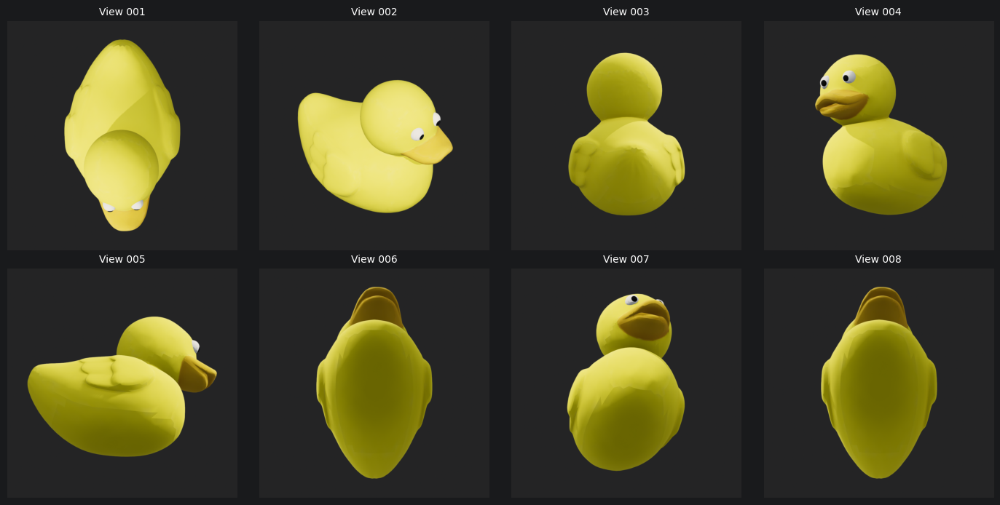

In [4]:
uid_value = current_object["uid"]
uid = uid_value[0] if isinstance(uid_value, (list, tuple)) else uid_value
print(f"=== Processing UID: {uid} ===")
mesh = current_object["mesh"][0] if isinstance(current_object["mesh"], list) else current_object["mesh"]
output_dir = f"rendered_views/{uid}"
rendered_info = render_n_views(mesh, n_views=6, output_dir=output_dir)
show_rendered_grid(output_dir)

Get masks for every image

rendered_views/b5c9d06f19be4c92a1708515f6655573/view_001.png
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


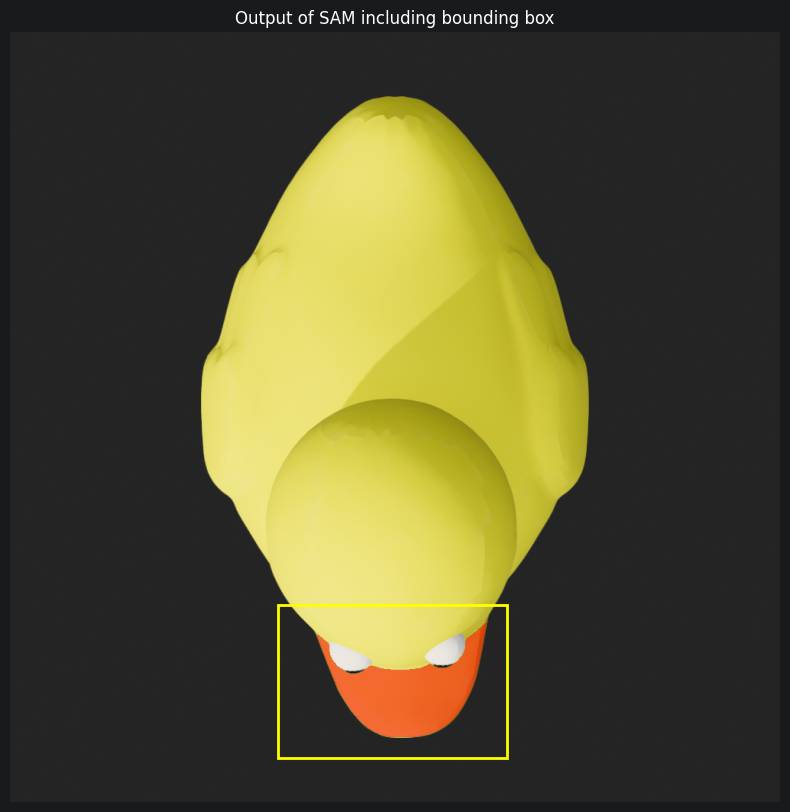

rendered_views/b5c9d06f19be4c92a1708515f6655573/view_002.png
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


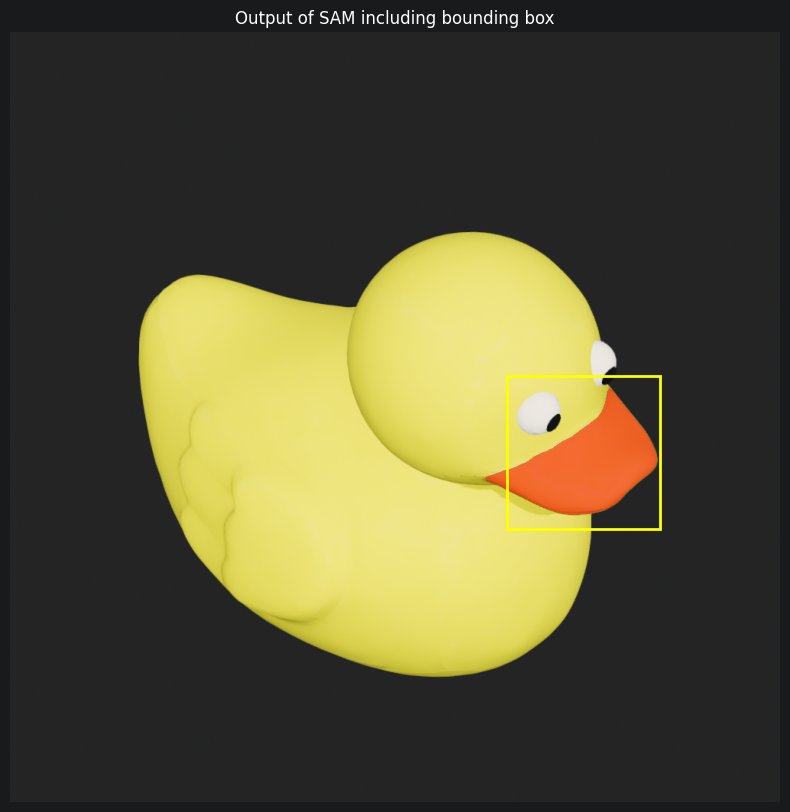

rendered_views/b5c9d06f19be4c92a1708515f6655573/view_004.png
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


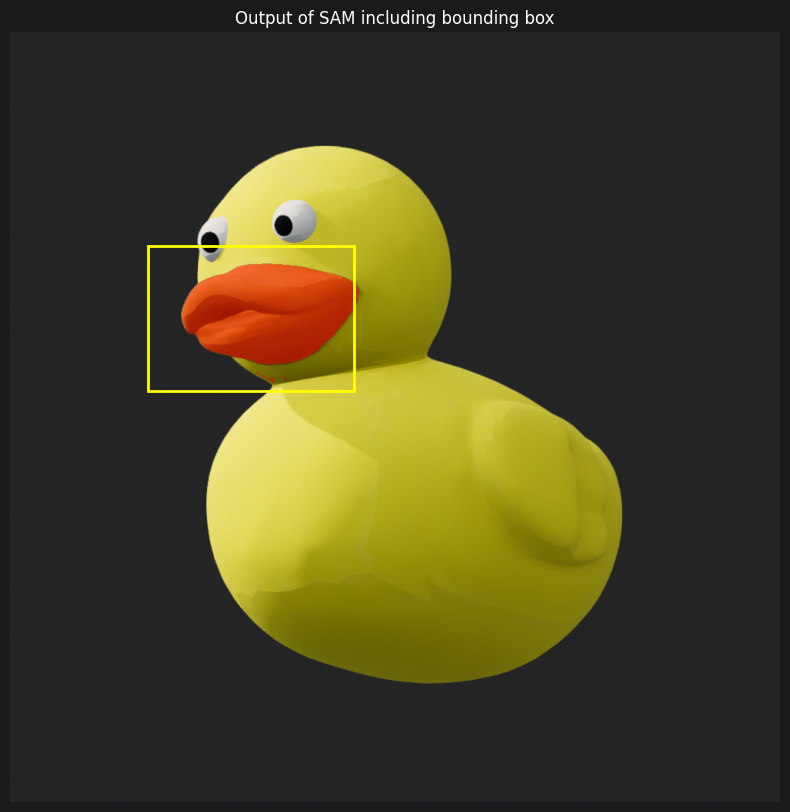

rendered_views/b5c9d06f19be4c92a1708515f6655573/view_004.png
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


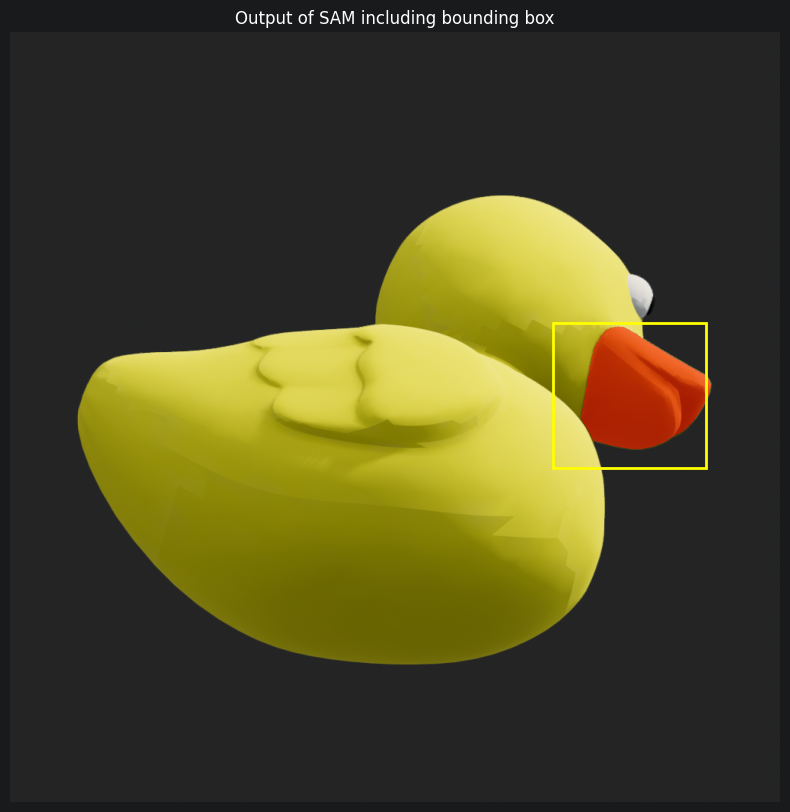

rendered_views/b5c9d06f19be4c92a1708515f6655573/view_004.png
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


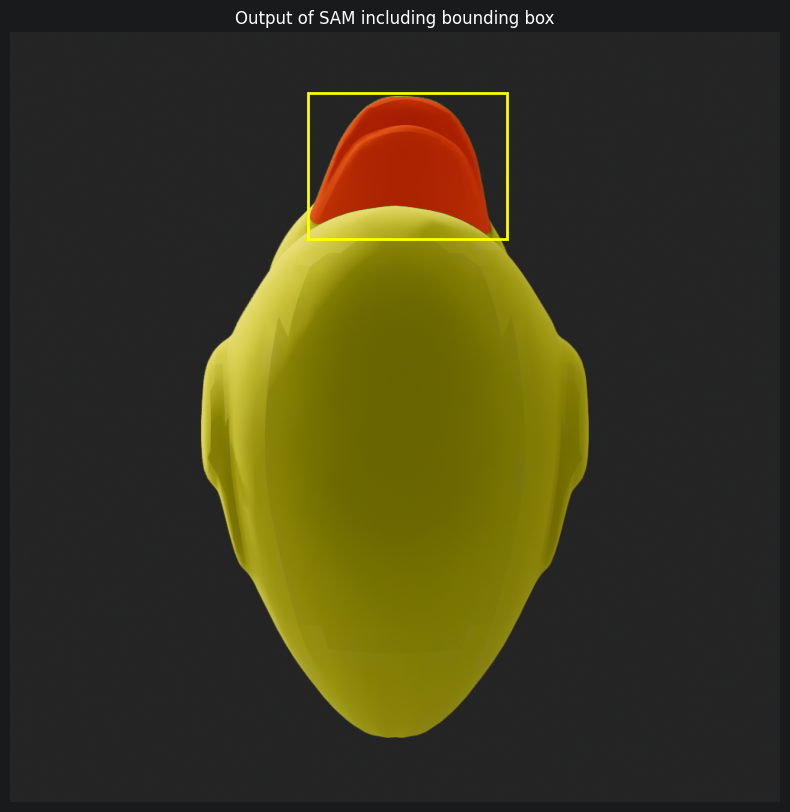

In [5]:
valid_masks_set = []
res1, path1 = rendered_info[0]
print(path1)
xmin, ymin, xmax, ymax = 350,750,650,950
mask = segment_image(path1, xmin, ymin, xmax, ymax)
visualize_segmentation(
    image_path=path1, mask=mask,
    x1=xmin, y1=ymin, x2=xmax, y2=ymax
)
valid_masks_set.append((mask, res1))

res2, path2 = rendered_info[1]
print(path2)
xmin, ymin, xmax, ymax = 650,450,850,650
mask = segment_image(path2, xmin, ymin, xmax, ymax)
visualize_segmentation(
    image_path=path2, mask=mask,
    x1=xmin, y1=ymin, x2=xmax, y2=ymax
)
valid_masks_set.append((mask, res2))
#skip rendered_info[4] since it does not contain the beack
res4, path4 = rendered_info[3]
print(path4)
xmin, ymin, xmax, ymax = 180,280,450,470
mask = segment_image(path4, xmin, ymin, xmax, ymax)
visualize_segmentation(
    image_path=path4, mask=mask,
    x1=xmin, y1=ymin, x2=xmax, y2=ymax
)
valid_masks_set.append((mask, res4))

res5, path5 = rendered_info[4]
print(path4)
xmin, ymin, xmax, ymax = 710,380,910,570
mask = segment_image(path5, xmin, ymin, xmax, ymax)
visualize_segmentation(
    image_path=path5, mask=mask,
    x1=xmin, y1=ymin, x2=xmax, y2=ymax
)
valid_masks_set.append((mask, res5))

res6, path6 = rendered_info[5]
print(path4)
xmin, ymin, xmax, ymax = 390,80,650,270
mask = segment_image(path6, xmin, ymin, xmax, ymax)
visualize_segmentation(
    image_path=path6, mask=mask,
    x1=xmin, y1=ymin, x2=xmax, y2=ymax
)
valid_masks_set.append((mask, res6))

Generate 3d mask from mask views

In [6]:
dense_mesh = mesh.subdivide()
colored_mesh, mask_submesh = project_masks_to_3d(dense_mesh, valid_masks_set)
display(mask_submesh.show())
display(colored_mesh.show())

Remove the masked part of 3d object

In [7]:
# Find selected faces (green)
face_mask = np.all(colored_mesh.visual.face_colors[:, :3] == [0, 255, 0], axis=1)


# Expand the mask by neighboring triangles
for _ in range(2):
    neighbors = dense_mesh.face_adjacency
    expanded = face_mask.copy()
    expanded[neighbors[face_mask[neighbors[:, 0]], 1]] = True
    expanded[neighbors[face_mask[neighbors[:, 1]], 0]] = True
    face_mask = expanded

# Delete selected faces
edited_mesh = dense_mesh.submesh([~face_mask], append=True)
# Visualize result
edited_mesh.show()

**Experimental**: Remove remaining small details that were not captured by the mask

In [8]:
from scipy.spatial import cKDTree
# Geometry of the removed region
removed_mesh = dense_mesh.submesh([face_mask], append=True)

# Split remaining mesh into connected components
components = edited_mesh.split(only_watertight=False)
# Spatial index of removed geometry
tree = cKDTree(removed_mesh.vertices)

# Thresholds relative to the original mesh size
extent = dense_mesh.extents.max()
max_size = extent * 0.1
max_distance = extent * 0.03

clean_components = []

for component in components:
    # Check component size
    is_small = component.extents.max() < max_size

    # Check proximity to deleted region
    distance, _ = tree.query(component.vertices)
    is_near = distance.min() < max_distance

    if is_small and is_near:
        print(f"Removed fragment: {len(component.faces)} faces")
    else:
        clean_components.append(component)

# Rebuild mesh
edited_mesh = trimesh.util.concatenate(clean_components)
edited_mesh.show()


Removed fragment: 356 faces
Removed fragment: 354 faces
Removed fragment: 4 faces
Removed fragment: 2 faces
Removed fragment: 18 faces
Removed fragment: 1 faces
Removed fragment: 1 faces
Removed fragment: 4 faces
Removed fragment: 4 faces
Removed fragment: 4 faces
Removed fragment: 4 faces
Removed fragment: 8 faces
Removed fragment: 480 faces
Removed fragment: 280 faces
Removed fragment: 280 faces
Removed fragment: 296 faces
Removed fragment: 480 faces
Removed fragment: 360 faces
Removed fragment: 528 faces
Removed fragment: 158 faces
Removed fragment: 161 faces
Removed fragment: 528 faces
Removed fragment: 360 faces
Removed fragment: 4 faces
Removed fragment: 1 faces
Removed fragment: 4 faces
Removed fragment: 1 faces


Fill the holes of edited mesh

In [9]:
# Identify edges between removed and preserved faces in the ORIGINAL dense mesh.
adj = dense_mesh.face_adjacency
cut = face_mask[adj[:, 0]] != face_mask[adj[:, 1]]
cut_edges = dense_mesh.face_adjacency_edges[cut]
cut_midpoints = dense_mesh.vertices[cut_edges].mean(axis=1)

# Find open edges on the CLEANED edited mesh (vertex indices may have changed).
edges, counts = np.unique(edited_mesh.edges_sorted, axis=0, return_counts=True)
open_edges = edges[counts == 1]
open_midpoints = edited_mesh.vertices[open_edges].mean(axis=1)

# Keep only open edges that match the deletion boundary geometrically.
from scipy.spatial import cKDTree
if len(cut_midpoints) and len(open_midpoints):
    distances, _ = cKDTree(cut_midpoints).query(open_midpoints)
    boundary_edges = open_edges[distances < max(1e-8, dense_mesh.extents.max() * 1e-6)]
else:
    boundary_edges = np.empty((0, 2), dtype=int)

print(f"Cut edges in original mesh: {len(cut_edges)}")
print(f"Open edges on cleaned mesh: {len(open_edges)}")
print(f"Remaining cut-boundary edges: {len(boundary_edges)}")

# Visualize the detected boundary as line segments over the edited mesh.
if len(boundary_edges):
    boundary_lines = trimesh.load_path(edited_mesh.vertices[boundary_edges])
    trimesh.Scene([edited_mesh, boundary_lines]).show()

Cut edges in original mesh: 250
Open edges on cleaned mesh: 4298
Remaining cut-boundary edges: 129


In [10]:

import networkx as nx

G = nx.Graph()
G.add_edges_from(boundary_edges)

loops = [
    G.subgraph(nodes).copy()
    for nodes in nx.connected_components(G)
]

for i, loop in enumerate(loops):
    closed = all(degree == 2 for _, degree in loop.degree())
    print(f"Component {i}: {loop.number_of_edges()} edges, closed={closed}")


Component 0: 41 edges, closed=False
Component 1: 42 edges, closed=False
Component 2: 16 edges, closed=True
Component 3: 10 edges, closed=False
Component 4: 20 edges, closed=False


In [11]:

import networkx as nx
import numpy as np

# Get all open boundary edges of the edited mesh
edges, counts = np.unique(
    edited_mesh.edges_sorted,
    axis=0,
    return_counts=True
)
all_boundary_edges = edges[counts == 1]

# Build graph of all boundary edges
G_all = nx.Graph()
G_all.add_edges_from(all_boundary_edges)

# Find boundary components connected to our cut edges
cut_vertices = set(boundary_edges.flatten())

related_components = [
    G_all.subgraph(nodes).copy()
    for nodes in nx.connected_components(G_all)
    if cut_vertices.intersection(nodes)
]

for i, component in enumerate(related_components):
    degrees = [d for _, d in component.degree()]
    print(
        f"Component {i}: "
        f"{component.number_of_edges()} edges, "
        f"closed={all(d == 2 for d in degrees)}, "
        f"endpoints={degrees.count(1)}, "
        f"branches={sum(d > 2 for d in degrees)}"
    )


Component 0: 141 edges, closed=True, endpoints=0, branches=0
Component 1: 188 edges, closed=True, endpoints=0, branches=0
Component 2: 16 edges, closed=True, endpoints=0, branches=0
Component 3: 219 edges, closed=True, endpoints=0, branches=0


In [12]:
import trimesh
import numpy as np

colors = [
    [255, 0, 0, 255],    # Red
    [0, 255, 0, 255],    # Green
    [0, 0, 255, 255]     # Blue
]

scene = trimesh.Scene()
scene.add_geometry(edited_mesh)

for i, loop in enumerate(related_components):
    edges = np.array(list(loop.edges()), dtype=int)

    # Convert edge vertex indices into 3D line segments
    segments = edited_mesh.vertices[edges]

    path = trimesh.load_path(segments)
    path.colors = np.tile(
        colors[i % len(colors)],
        (len(path.entities), 1)
    )

    scene.add_geometry(path)

scene.show()